# 02_model_11：双模型真实气象训练与模拟气象预报测试

本版本基于 02_model_08 的初版直接预测框架进行调整：Ridge 与 ExtraTrees 两个模型都在训练阶段使用目标日真实气象特征，测试阶段统一使用模拟气象预报特征。这样可以在相同的信息边界下比较两种模型。

目标日仍输出完整 144 个 10 分钟负荷点。测试集主结果采用 0% 气象接近度，即以前一日气象作为持久性模拟预报；同时保留 0%、25%、50%、75% 和 100% 情景，分析预测结果对气象预报误差的敏感性。100% 仅作为目标日真实气象的理想参考，不代表实际部署性能。

## 1. 分析对象、数据选择与预测任务

分析对象是全市三区合计负荷 `Z_total = Z1 + Z2 + Z3`。选择总负荷的理由是：调度首先关心全市电源侧需要承担的总负荷，三区合计还能减弱局部随机波动，更接近实际调度对象。原始记录保持 10 分钟粒度，每个完整日包含 144 个点。

本项目按时间顺序划分数据：2017 年 1 月至 10 月的目标日用于训练，2017 年 11 月至 12 月的目标日用于测试，共评价 60 个未来日。测试集不参与模型拟合，避免把未来信息带回训练过程。只保留时间顺序正确、采样间隔完整且含有 144 个点的日曲线。

预测任务是：在目标日开始前，使用前一天和前一周同日的负荷曲线，加上目标日提前可知的星期、月份和周末特征，预测目标日完整的 144 点负荷曲线。模型是多输出回归模型，不是递归式逐点预测，因此不会把前一个预测值再次作为下一步输入。

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
FIG_DIR = 'figures'
SPLIT = pd.Timestamp('2017-11-01')
MODEL_NAMES = ['Ridge多输出回归', 'ExtraTrees多输出回归']
print('预测频率：10分钟；预测步长：1天；输出点数：144')

预测频率：10分钟；预测步长：1天；输出点数：144


### 1.1 数据读取和完整日曲线

下面读取原始数据，检查时间顺序、采样间隔、缺失值和完整日结构，并构造全市三区合计负荷。

In [2]:
df = pd.read_csv('data/题4_城市电力负荷.csv', encoding='utf-8-sig')
df.columns = ['DateTime', 'T', 'RH', 'WS', 'GDF', 'DF', 'Z1', 'Z2', 'Z3']
df['DateTime'] = pd.to_datetime(df['DateTime'], format='%m/%d/%Y %H:%M')
df = df.set_index('DateTime').sort_index()
df['Z_total'] = df[['Z1', 'Z2', 'Z3']].sum(axis=1)
assert not df.index.duplicated().any()
step_minutes = df.index.to_series().diff().dropna().dt.total_seconds().div(60)
assert step_minutes.eq(10).all()

WEATHER_COLS = ['T', 'RH', 'WS', 'GDF', 'DF']
day_profiles = {}
weather_profiles = {}
for day, group in df.groupby(df.index.normalize()):
    if len(group) == 144:
        day = pd.Timestamp(day)
        day_profiles[day] = group['Z_total'].to_numpy(dtype=float)
        weather_profiles[day] = {col: group[col].to_numpy(dtype=float) for col in WEATHER_COLS}

days = pd.DatetimeIndex(sorted(day_profiles))
print('完整天数:', len(days))
print('采样间隔:', step_minutes.mode().iloc[0], '分钟')

完整天数: 364
采样间隔: 10.0 分钟


## 2. 构造直接多输出预测样本

每个样本对应一个目标日 `D`。历史负荷和日历输入为：

```text
X_D = [D-1 的 144 点负荷曲线,
       D-7 的 144 点负荷曲线,
       目标日星期、月份、是否周末]
```

本版本再拼接目标日天气摘要：

```text
X_D_weather = [X_D,
               T、RH、WS、GDF、DF 各自的均值、最大值、最小值]
```

输出为目标日的 144 个负荷点。训练期使用目标日真实天气构造 `X_D_weather`；测试期不使用目标日真实天气，而是使用模拟气象预报构造测试特征。

In [3]:
def calendar_features(day):
    day = pd.Timestamp(day)
    return [
        np.sin(2 * np.pi * day.dayofweek / 7),
        np.cos(2 * np.pi * day.dayofweek / 7),
        np.sin(2 * np.pi * (day.month - 1) / 12),
        np.cos(2 * np.pi * (day.month - 1) / 12),
        int(day.dayofweek >= 5),
    ]

X, Y, target_dates = [], [], []
for target_day in days:
    if target_day - pd.Timedelta(days=1) not in day_profiles:
        continue
    if target_day - pd.Timedelta(days=7) not in day_profiles:
        continue
    features = np.concatenate([
        day_profiles[target_day - pd.Timedelta(days=1)],
        day_profiles[target_day - pd.Timedelta(days=7)],
        np.asarray(calendar_features(target_day), dtype=float),
    ])
    X.append(features)
    Y.append(day_profiles[target_day])
    target_dates.append(target_day)

X = np.asarray(X)
Y = np.asarray(Y)
target_dates = pd.DatetimeIndex(target_dates)
train_mask = target_dates < SPLIT
test_mask = target_dates >= SPLIT
X_train, Y_train = X[train_mask], Y[train_mask]
X_test, Y_test = X[test_mask], Y[test_mask]
test_dates = target_dates[test_mask]

def weather_summary(day_weather):
    return np.concatenate([
        np.array([day_weather[col].mean(), day_weather[col].max(), day_weather[col].min()])
        for col in WEATHER_COLS
    ])

def load_curve_features(target_day):
    return np.concatenate([
        day_profiles[target_day - pd.Timedelta(days=1)],
        day_profiles[target_day - pd.Timedelta(days=7)],
        np.asarray(calendar_features(target_day), dtype=float),
    ])

# 训练阶段使用目标日真实天气。
Xw_all = []
for target_day in target_dates:
    actual_weather = {col: weather_profiles[target_day][col] for col in WEATHER_COLS}
    Xw_all.append(np.r_[load_curve_features(target_day), weather_summary(actual_weather)])
Xw_all = np.asarray(Xw_all)
Xw_train = Xw_all[train_mask]

def simulated_weather_features(similarity):
    rows = []
    for target_day in test_dates:
        base_weather = {col: weather_profiles[target_day - pd.Timedelta(days=1)][col] for col in WEATHER_COLS}
        actual_weather = {col: weather_profiles[target_day][col] for col in WEATHER_COLS}
        simulated_weather = {
            col: base_weather[col] + similarity * (actual_weather[col] - base_weather[col])
            for col in WEATHER_COLS
        }
        rows.append(np.r_[load_curve_features(target_day), weather_summary(simulated_weather)])
    return np.asarray(rows)

similarity_levels = [0.0, 0.25, 0.50, 0.75, 1.0]
Xw_test_by_similarity = {s: simulated_weather_features(s) for s in similarity_levels}
TEST_WEATHER_SIMILARITY = 0.0
Xw_test = Xw_test_by_similarity[TEST_WEATHER_SIMILARITY]

print('X_train（无气象基准）:', X_train.shape, '| Y_train:', Y_train.shape)
print('Xw_train（训练期真实气象）:', Xw_train.shape)
print('X_test（无气象基准）:', X_test.shape, '| Y_test:', Y_test.shape)
print(f'Xw_test（{TEST_WEATHER_SIMILARITY:.0%} 模拟气象预报）:', Xw_test.shape)

X_train（无气象基准）: (297, 293) | Y_train: (297, 144)
Xw_train（训练期真实气象）: (297, 308)
X_test（无气象基准）: (60, 293) | Y_test: (60, 144)
Xw_test（0% 模拟气象预报）: (60, 308)


## 3. 训练两个采用气象特征的算法

本版本的核心比较对象仍是 Ridge 和 ExtraTrees，但两者使用完全相同的气象信息边界：

- **Ridge 多输出回归**：标准化输入后使用 L2 正则化，`alpha=10`。它可以压缩高度相关历史曲线和气象摘要的回归系数，适合日级样本较少、输入维度较高的场景。
- **ExtraTrees 多输出回归**：由多棵随机化回归树组成，固定使用 `n_estimators=200`、`max_depth=12`、`min_samples_leaf=2`、`max_features=0.7`，用于检验气象与历史负荷之间的非线性和特征交互。

两个模型都使用 `Xw_train` 拟合，训练特征中的气象变量来自训练期目标日真实观测；测试时都使用 `Xw_test`，其中气象变量来自 0% 接近度的模拟预报，即前一日持久性气象。这样比较的是模型差异，而不是一个模型有天气、另一个模型没有天气。

参数仍是固定基线，不代表所有 Ridge 或 ExtraTrees 的最优性能。若进一步调参，应只在训练期内部进行滚动时间验证，最后锁定测试集。

In [4]:
models = {
    'Ridge多输出回归': make_pipeline(
        StandardScaler(), Ridge(alpha=10.0)
    ),
    'ExtraTrees多输出回归': ExtraTreesRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=2,
        max_features=0.7,
        n_jobs=1,
        random_state=0,
    ),
}

predictions = {}
for name, model in models.items():
    model.fit(Xw_train, Y_train)
    predictions[name] = model.predict(Xw_test)
print(f'两个模型均已训练：训练期使用真实气象，测试期使用 {TEST_WEATHER_SIMILARITY:.0%} 模拟气象预报')

两个模型均已训练：训练期使用真实气象，测试期使用 0% 模拟气象预报


## 4. 两个模型的指标评价

本节主要用 RMSE、MAE 和 sMAPE 判断完整 144 点负荷曲线的预测误差，并把 R²作为辅助信息。主测试场景为 2017-11-01 至 2017-12-30，共 60 个目标日；Ridge 与 ExtraTrees 都使用训练期真实气象和测试期 0% 模拟气象预报。

在这一主测试情景下，Ridge 的曲线 RMSE、MAE、sMAPE 分别为 2,494.50 kW、1,767.05 kW、2.72%；ExtraTrees 分别为 3,910.83 kW、3,142.59 kW、4.77%。逐时间点平均 R²为 0.2550 和 −1.5828，曲线展平 R²为 0.9692 和 0.9243。Ridge 在当前测试窗的主要误差指标更低，但这只说明当前参数、当前气象摘要和当前时间外推区间下 Ridge 更好。

In [5]:
def smape(y_true, pred):
    return np.mean(2 * np.abs(pred - y_true) /
                   (np.abs(y_true) + np.abs(pred) + 1e-9)) * 100

metric_rows = []
for name, pred in predictions.items():
    mse = mean_squared_error(Y_test, pred)
    metric_rows.append({
        '模型': name,
        '曲线MSE(kW²)': mse,
        '曲线RMSE(kW)': np.sqrt(mse),
        '曲线MAE(kW)': mean_absolute_error(Y_test, pred),
        '曲线sMAPE%': smape(Y_test, pred),
        '曲线归一化RMSE%': np.sqrt(mse) / np.mean(np.abs(Y_test)) * 100,
        '曲线逐时间点平均R2': r2_score(Y_test, pred),
        '曲线展平R2': r2_score(Y_test.ravel(), pred.ravel()),
    })

summary_rows = []
for name, pred in predictions.items():
    for label, fn in [('日用电量(kWh)', lambda x: x.sum(axis=1) / 6),
                      ('日峰值(kW)', lambda x: x.max(axis=1)),
                      ('日谷值(kW)', lambda x: x.min(axis=1))]:
        y_true, y_pred = fn(Y_test), fn(pred)
        mse = mean_squared_error(y_true, y_pred)
        summary_rows.append({
            '模型': name,
            '目标': label,
            'MSE': mse,
            'RMSE': np.sqrt(mse),
            'MAE': mean_absolute_error(y_true, y_pred),
            'sMAPE%': smape(y_true, y_pred),
            '归一化RMSE%': np.sqrt(mse) / np.mean(np.abs(y_true)) * 100,
            'R2': r2_score(y_true, y_pred),
        })

curve_metrics = pd.DataFrame(metric_rows)
summary_metrics = pd.DataFrame(summary_rows)
display(curve_metrics.style.format({
    '曲线MSE(kW²)': '{:,.0f}', '曲线RMSE(kW)': '{:,.2f}',
    '曲线MAE(kW)': '{:,.2f}', '曲线sMAPE%': '{:.2f}%',
    '曲线归一化RMSE%': '{:.2f}%', '曲线逐时间点平均R2': '{:.4f}', '曲线展平R2': '{:.4f}'
}))
display(summary_metrics.style.format({
    'MSE': '{:,.0f}', 'RMSE': '{:,.2f}', 'MAE': '{:,.2f}',
    'sMAPE%': '{:.2f}%', '归一化RMSE%': '{:.2f}%', 'R2': '{:.4f}'
}))

,模型,曲线MSE(kW²),曲线RMSE(kW),曲线MAE(kW),曲线sMAPE%,曲线归一化RMSE%,曲线逐时间点平均R2,曲线展平R2
0,Ridge多输出回归,"6,222,532","2,494.50","1,767.05",2.72%,3.87%,0.2550,0.9692
1,ExtraTrees多输出回归,"15,294,612","3,910.83","3,142.59",4.77%,6.07%,-1.5828,0.9243


,模型,目标,MSE,RMSE,MAE,sMAPE%,归一化RMSE%,R2
0,Ridge多输出回归,日用电量(kWh),"1,252,882,827","35,396.08","26,259.55",1.70%,2.29%,0.5752
1,Ridge多输出回归,日峰值(kW),"8,434,478","2,904.22","2,231.16",2.47%,3.24%,0.1873
2,Ridge多输出回归,日谷值(kW),"5,055,846","2,248.52","1,503.20",3.48%,5.09%,0.5385
3,ExtraTrees多输出回归,日用电量(kWh),"4,104,358,934","64,065.27","53,304.09",3.43%,4.14%,-0.3915
4,ExtraTrees多输出回归,日峰值(kW),"20,478,108","4,525.27","3,835.90",4.24%,5.05%,-0.9733
5,ExtraTrees多输出回归,日谷值(kW),"15,693,429","3,961.49","3,476.03",7.73%,8.97%,-0.4324


## 5. 与前一天、前一周持久性基线比较

前一天和前一周曲线不是训练出来的时间序列模型，而是无需拟合参数的业务基线：

```text
前一天基线：ŷ_D = y_{D-1}
前一周基线：ŷ_D = y_{D-7}
```

在 2017-11-01 至 2017-12-30 这个测试窗内，Ridge 的曲线 RMSE 为 2,442.59 kW，低于前一天基线的 3,232.75 kW 和前一周基线的 2,986.68 kW；MAE、sMAPE 和归一化 RMSE 也低于两个基线。因此，Ridge 在这个测试区间获得了超过简单持久性规则的预测增益。ExtraTrees 的 RMSE 为 3,902.17 kW，没有超过任一基线。

这里的结论仍然是条件性的：测试集只有年末 60 天，且训练期与测试期存在季节分布变化。它支持“Ridge 在当前测试窗内有增量价值”，不支持“Ridge 在所有时期都一定优于树模型”。R²表中的“逐时间点平均 R²”和“曲线展平 R²”分别对应不同聚合口径，应结合 RMSE、MAE 和 sMAPE 一起解读。

In [6]:
baseline_rows = []
for name, lag in [('前一天曲线基线', 1), ('前一周曲线基线', 7)]:
    baseline = np.asarray([day_profiles[d - pd.Timedelta(days=lag)] for d in test_dates])
    mse = mean_squared_error(Y_test, baseline)
    baseline_rows.append({
        '模型': name,
        '曲线MSE(kW²)': mse,
        '曲线RMSE(kW)': np.sqrt(mse),
        '曲线MAE(kW)': mean_absolute_error(Y_test, baseline),
        '曲线sMAPE%': smape(Y_test, baseline),
        '曲线归一化RMSE%': np.sqrt(mse) / np.mean(np.abs(Y_test)) * 100,
        '曲线逐时间点平均R2': r2_score(Y_test, baseline),
        '曲线展平R2': r2_score(Y_test.ravel(), baseline.ravel()),
    })
baseline_metrics = pd.DataFrame(baseline_rows)
all_curve_metrics = pd.concat([curve_metrics, baseline_metrics], ignore_index=True)
display(all_curve_metrics.style.format({
    '曲线MSE(kW²)': '{:,.0f}', '曲线RMSE(kW)': '{:,.2f}',
    '曲线MAE(kW)': '{:,.2f}', '曲线sMAPE%': '{:.2f}%',
    '曲线归一化RMSE%': '{:.2f}%', '曲线逐时间点平均R2': '{:.4f}', '曲线展平R2': '{:.4f}'
}))

,模型,曲线MSE(kW²),曲线RMSE(kW),曲线MAE(kW),曲线sMAPE%,曲线归一化RMSE%,曲线逐时间点平均R2,曲线展平R2
0,Ridge多输出回归,"6,222,532","2,494.50","1,767.05",2.72%,3.87%,0.2550,0.9692
1,ExtraTrees多输出回归,"15,294,612","3,910.83","3,142.59",4.77%,6.07%,-1.5828,0.9243
2,前一天曲线基线,"10,450,647","3,232.75","2,122.43",3.41%,5.02%,-0.0419,0.9483
3,前一周曲线基线,"8,920,256","2,986.68","2,150.35",3.40%,4.64%,-0.1068,0.9558


## 6. 两个模型的模拟气象预报敏感性

前面的主结果使用 0% 气象接近度，代表测试日只能拿到前一日持久性天气作为模拟预报。本节保持两个模型的训练结果不变，分别把测试气象替换为 0%、25%、50%、75% 和 100% 接近真实天气的情景，观察模型对气象预报误差的敏感性。

训练阶段两个模型都使用训练期目标日真实天气；测试阶段只改变模拟天气特征。

```text
模拟气象 = 前一日气象 + 接近度 ×（目标日真实气象 − 前一日气象）
```

100% 情景使用目标日真实气象，仅作为理想信息参考，不是实际部署评估。不同接近度结果用于敏感性分析，不表示因果关系。

In [7]:
# 训练期持久性天气误差：用于展示误差尺度；模型测试特征由模拟气象预报构造。
weather_error_rows = []
for target_day in days:
    if target_day >= SPLIT or target_day - pd.Timedelta(days=1) not in weather_profiles:
        continue
    for col in WEATHER_COLS:
        error = weather_profiles[target_day - pd.Timedelta(days=1)][col] - weather_profiles[target_day][col]
        weather_error_rows.append({
            '目标日': target_day, '变量': col,
            'MAE': np.mean(np.abs(error)),
            'RMSE': np.sqrt(np.mean(error ** 2)),
        })
weather_error_basis = pd.DataFrame(weather_error_rows).groupby('变量', as_index=False).agg(
    训练期MAE=('MAE', 'mean'), 训练期RMSE=('RMSE', 'mean')
)
display(weather_error_basis.style.format({'训练期MAE': '{:,.3f}', '训练期RMSE': '{:,.3f}'}))

weather_predictions = {name: {} for name in models}
weather_gap_rows = []
weather_metric_rows = []
for similarity in similarity_levels:
    Xw_test_sim = Xw_test_by_similarity[similarity]
    for name, model in models.items():
        pred = model.predict(Xw_test_sim)
        weather_predictions[name][similarity] = pred
        mse = mean_squared_error(Y_test, pred)
        weather_metric_rows.append({
            '模型': name,
            '气象接近度%': similarity * 100,
            '曲线MSE(kW²)': mse,
            '曲线RMSE(kW)': np.sqrt(mse),
            '曲线MAE(kW)': mean_absolute_error(Y_test, pred),
            '曲线sMAPE%': smape(Y_test, pred),
            '曲线归一化RMSE%': np.sqrt(mse) / np.mean(np.abs(Y_test)) * 100,
            '曲线逐时间点平均R2': r2_score(Y_test, pred),
            '曲线展平R2': r2_score(Y_test.ravel(), pred.ravel()),
            '日用电量RMSE(kWh)': np.sqrt(np.mean((Y_test.sum(axis=1) / 6 - pred.sum(axis=1) / 6) ** 2)),
            '日用电量sMAPE%': smape(Y_test.sum(axis=1) / 6, pred.sum(axis=1) / 6),
        })

    for target_day in test_dates:
        base_weather = {col: weather_profiles[target_day - pd.Timedelta(days=1)][col] for col in WEATHER_COLS}
        actual_weather = {col: weather_profiles[target_day][col] for col in WEATHER_COLS}
        for col in WEATHER_COLS:
            simulated = base_weather[col] + similarity * (actual_weather[col] - base_weather[col])
            gap = simulated - actual_weather[col]
            weather_gap_rows.append({
                '目标日': target_day, '气象接近度%': similarity * 100, '变量': col,
                '模拟预报MAE': np.mean(np.abs(gap)),
                '模拟预报RMSE': np.sqrt(np.mean(gap ** 2)),
            })

weather_gap_df = pd.DataFrame(weather_gap_rows)
weather_metrics_df = pd.DataFrame(weather_metric_rows)
print('测试集持久性天气预报误差（气象接近度 0%）：')
display(weather_gap_df[weather_gap_df['气象接近度%'] == 0].groupby('变量', as_index=False)[['模拟预报MAE', '模拟预报RMSE']].mean().style.format({
    '模拟预报MAE': '{:,.3f}', '模拟预报RMSE': '{:,.3f}'
}))
print('两个模型：不同气象接近度下的测试效果')
display(weather_metrics_df.style.format({
    '气象接近度%': '{:.0f}%', '曲线MSE(kW²)': '{:,.0f}',
    '曲线RMSE(kW)': '{:,.2f}', '曲线MAE(kW)': '{:,.2f}',
    '曲线sMAPE%': '{:.2f}%', '曲线归一化RMSE%': '{:.2f}%',
    '曲线逐时间点平均R2': '{:.4f}', '曲线展平R2': '{:.4f}',
    '日用电量RMSE(kWh)': '{:,.2f}', '日用电量sMAPE%': '{:.2f}%'
}))

,变量,训练期MAE,训练期RMSE
0,DF,37.365,71.584
1,GDF,53.237,102.462
2,RH,10.428,12.418
3,T,1.659,1.995
4,WS,0.582,0.842


测试集持久性天气预报误差（气象接近度 0%）：


,变量,模拟预报MAE,模拟预报RMSE
0,DF,22.946,47.264
1,GDF,30.950,66.866
2,RH,9.643,11.505
3,T,2.022,2.504
4,WS,0.722,1.007


两个模型：不同气象接近度下的测试效果


,模型,气象接近度%,曲线MSE(kW²),曲线RMSE(kW),曲线MAE(kW),曲线sMAPE%,曲线归一化RMSE%,曲线逐时间点平均R2,曲线展平R2,日用电量RMSE(kWh),日用电量sMAPE%
0,Ridge多输出回归,0%,"6,222,532","2,494.50","1,767.05",2.72%,3.87%,0.2550,0.9692,"35,396.08",1.70%
1,ExtraTrees多输出回归,0%,"15,294,612","3,910.83","3,142.59",4.77%,6.07%,-1.5828,0.9243,"64,065.27",3.43%
2,Ridge多输出回归,25%,"6,280,987","2,506.19","1,772.25",2.72%,3.89%,0.2428,0.9689,"35,542.41",1.68%
3,ExtraTrees多输出回归,25%,"15,380,444","3,921.79","3,153.46",4.78%,6.09%,-1.6021,0.9239,"64,346.01",3.45%
4,Ridge多输出回归,50%,"6,326,334","2,515.22","1,776.89",2.73%,3.90%,0.2357,0.9687,"35,703.76",1.69%
5,ExtraTrees多输出回归,50%,"15,402,403","3,924.59","3,157.26",4.79%,6.09%,-1.6065,0.9237,"64,427.78",3.46%
6,Ridge多输出回归,75%,"6,353,764","2,520.67","1,779.22",2.74%,3.91%,0.2336,0.9685,"35,923.06",1.69%
7,ExtraTrees多输出回归,75%,"15,372,551","3,920.78","3,154.30",4.79%,6.09%,-1.5981,0.9239,"64,375.26",3.45%
8,Ridge多输出回归,100%,"6,341,460","2,518.23","1,777.91",2.74%,3.91%,0.2365,0.9686,"36,077.48",1.69%
9,ExtraTrees多输出回归,100%,"15,294,215","3,910.78","3,144.52",4.77%,6.07%,-1.5807,0.9243,"64,116.34",3.43%


## 7. 气象接近度与预测准确度

图 4 的左图同时展示 Ridge 和 ExtraTrees 在不同模拟气象接近度下的曲线准确度，纵轴使用 `100 - sMAPE`，越高表示相对误差越小。右图展示不同气象变量的模拟预报 RMSE。

Ridge 的曲线 RMSE 在 0%、25%、50%、75%、100% 情景下分别为 2,494.50、2,506.19、2,515.22、2,520.67、2,518.23 kW；ExtraTrees 分别为 3,910.83、3,921.79、3,924.59、3,920.78、3,910.78 kW。两条曲线都没有随气象接近度单调改善，说明当前摘要和模拟方式没有呈现稳定的气象边际增益。

这组结果不能推出“气象没有作用”。它反映的是：两个模型都在真实气象上训练，但测试阶段使用了模拟预报；当前气象输入形式、训练测试分布差异和确定性模拟方式共同决定了结果。

C:\Users\lenovo\AppData\Local\Temp\ipykernel_4008\1087244805.py:24: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  fig.suptitle('图4  两个模型的模拟气象敏感性分析', y=1.02); fig.tight_layout()
C:\Users\lenovo\AppData\Local\Temp\ipykernel_4008\1087244805.py:25: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  fig.savefig(f'{FIG_DIR}/fig_B11_weather_sensitivity.png', dpi=160, bbox_inches='tight')


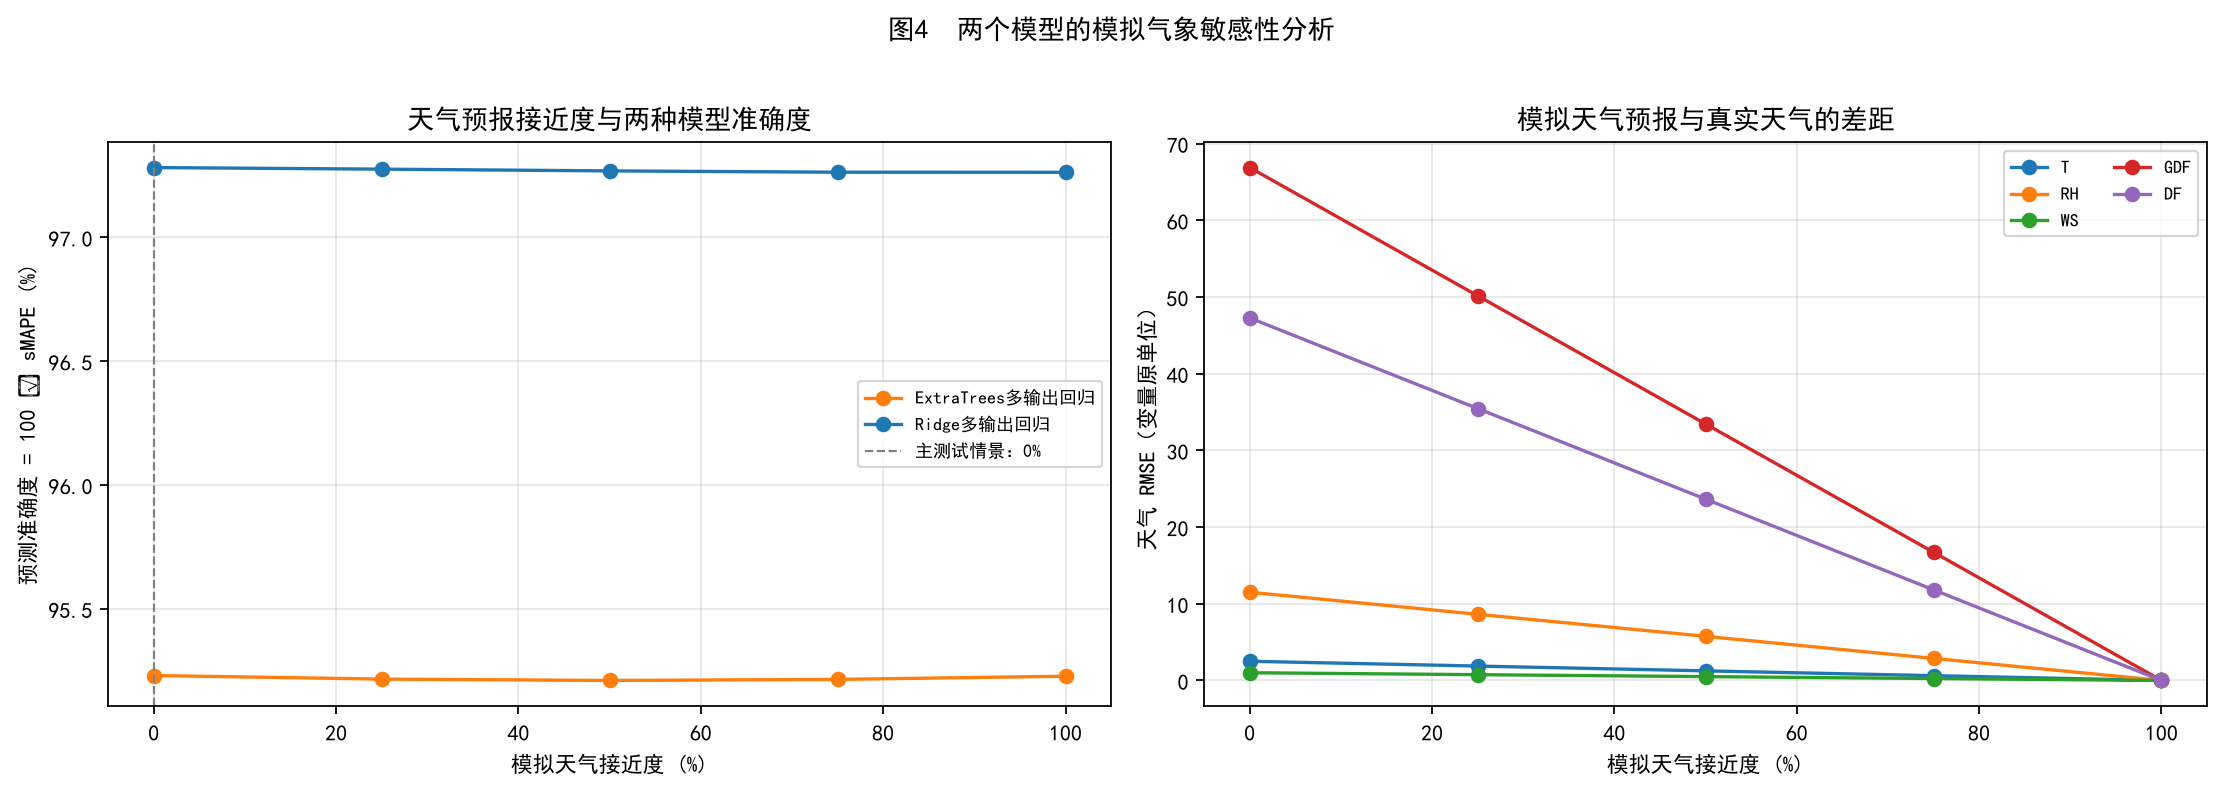

In [8]:
# 图4：两个模型的气象预报接近度、天气误差和负荷预测准确度
from IPython.display import Image, display
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
weather_curve = weather_metrics_df.copy()
weather_curve['曲线准确度%'] = 100 - weather_curve['曲线sMAPE%']
colors = {'Ridge多输出回归': '#1f77b4', 'ExtraTrees多输出回归': '#ff7f0e'}
for name, sub in weather_curve.groupby('模型'):
    sub = sub.sort_values('气象接近度%')
    axes[0].plot(sub['气象接近度%'], sub['曲线准确度%'], marker='o', color=colors[name], label=name)
axes[0].axvline(TEST_WEATHER_SIMILARITY * 100, color='gray', ls='--', lw=1.0, label='主测试情景：0%')
axes[0].set_xlabel('模拟天气接近度 (%)')
axes[0].set_ylabel('预测准确度 = 100 − sMAPE (%)')
axes[0].set_title('天气预报接近度与两种模型准确度')
axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8)

weather_gap_plot = weather_gap_df.groupby(['气象接近度%', '变量'], as_index=False)['模拟预报RMSE'].mean()
for col in WEATHER_COLS:
    sub = weather_gap_plot[weather_gap_plot['变量'] == col]
    axes[1].plot(sub['气象接近度%'], sub['模拟预报RMSE'], marker='o', label=col)
axes[1].set_xlabel('模拟天气接近度 (%)')
axes[1].set_ylabel('天气 RMSE（变量原单位）')
axes[1].set_title('模拟天气预报与真实天气的差距')
axes[1].grid(alpha=0.3); axes[1].legend(ncol=2, fontsize=8)
fig.suptitle('图4  两个模型的模拟气象敏感性分析', y=1.02); fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_B11_weather_sensitivity.png', dpi=160, bbox_inches='tight')
display(Image(filename=f'{FIG_DIR}/fig_B11_weather_sensitivity.png'))
plt.close(fig)

## 8. 测试集可视化与结果解释

本节代码生成四类互相补充的图：

1. **测试日 144 点曲线图**：展示两个模型在 0% 模拟气象预报下的完整日内预测；
2. **测试期日用电量图**：展示两个模型对测试期日用电量的预测；
3. **百分比指标对比图**：用归一化 RMSE 和日用电量 sMAPE 比较模型与时间序列基线；
4. **气象敏感性图**：比较两个模型在不同模拟天气接近度下的预测准确度。

曲线图和指标图使用同一主测试情景，气象敏感性图再补充展示从持久性天气到理想真实天气的变化。

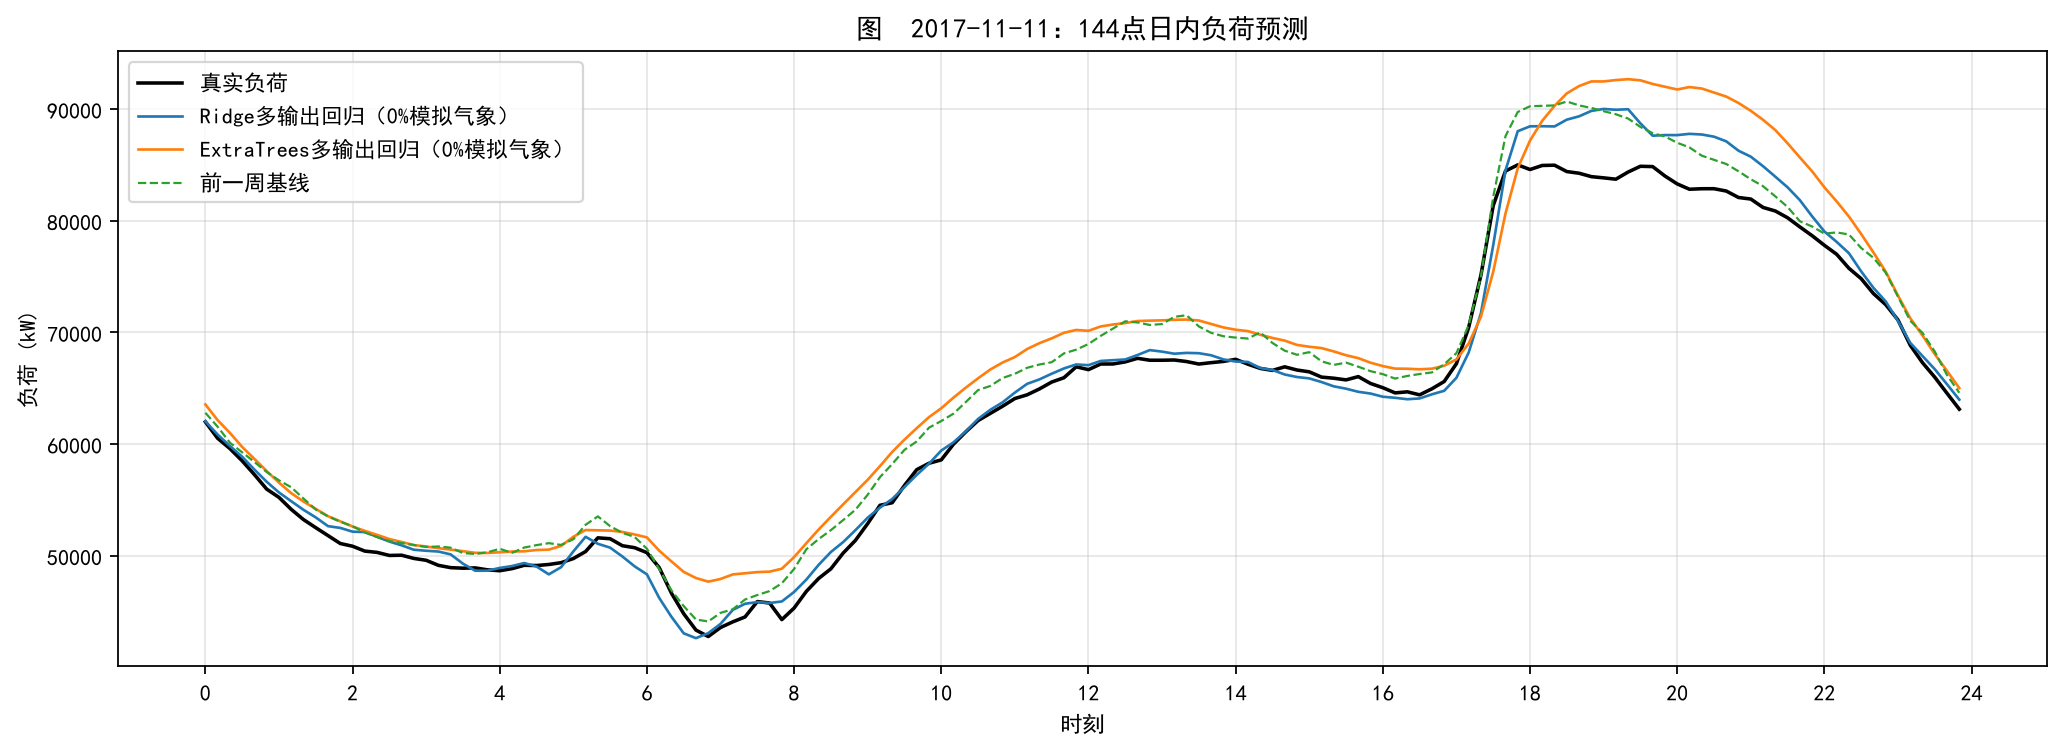

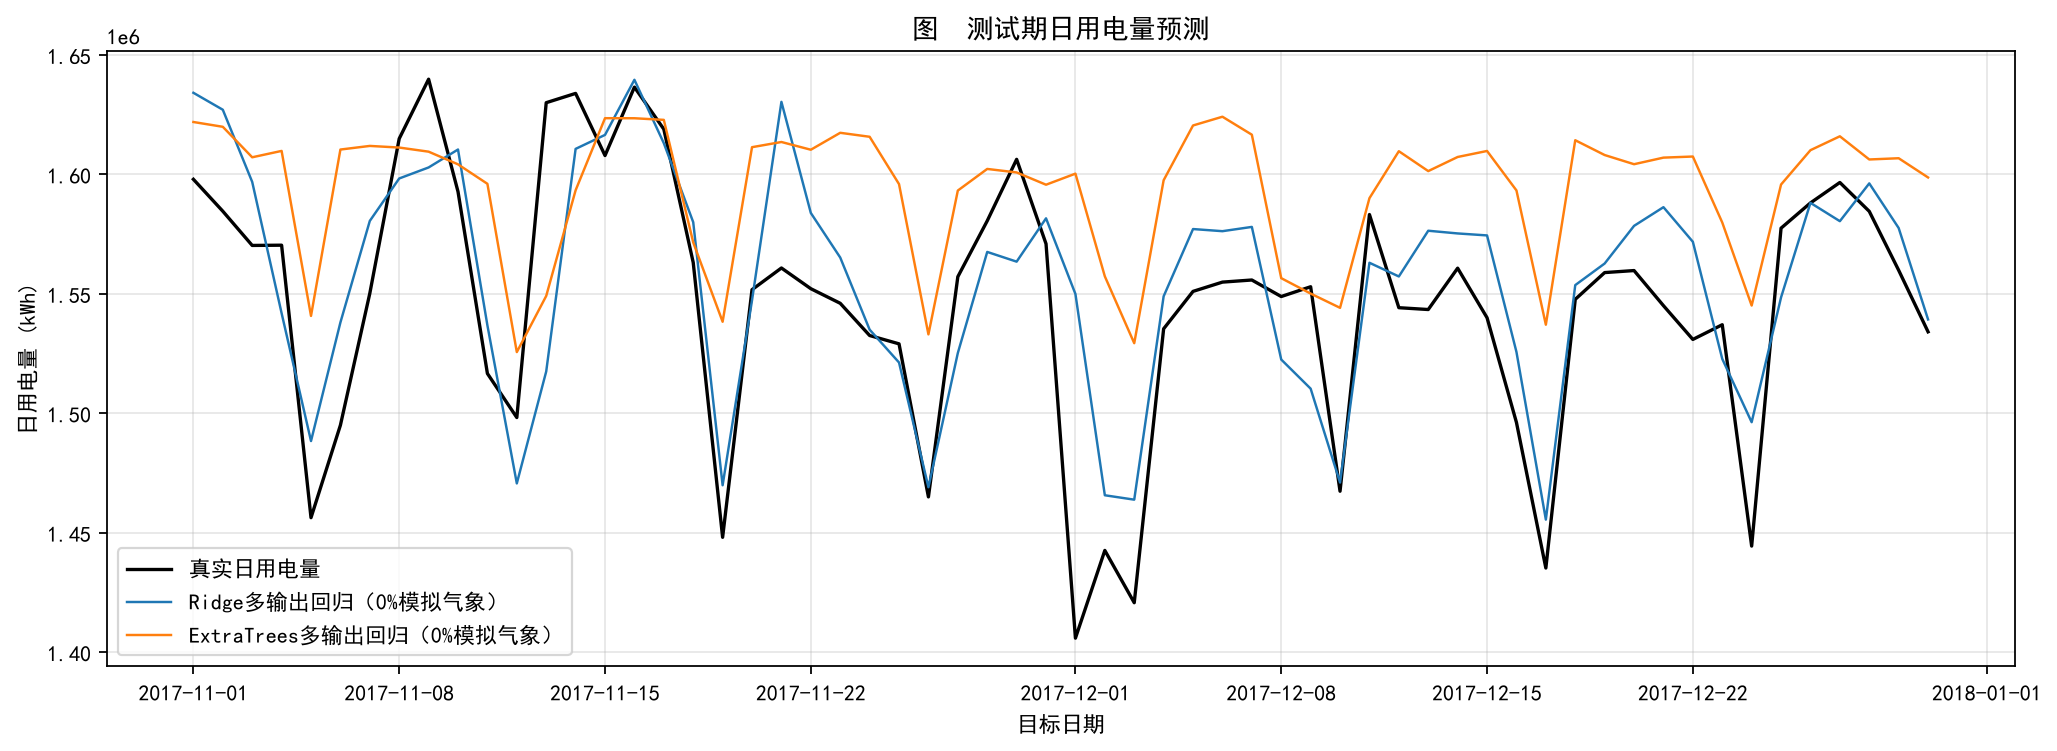

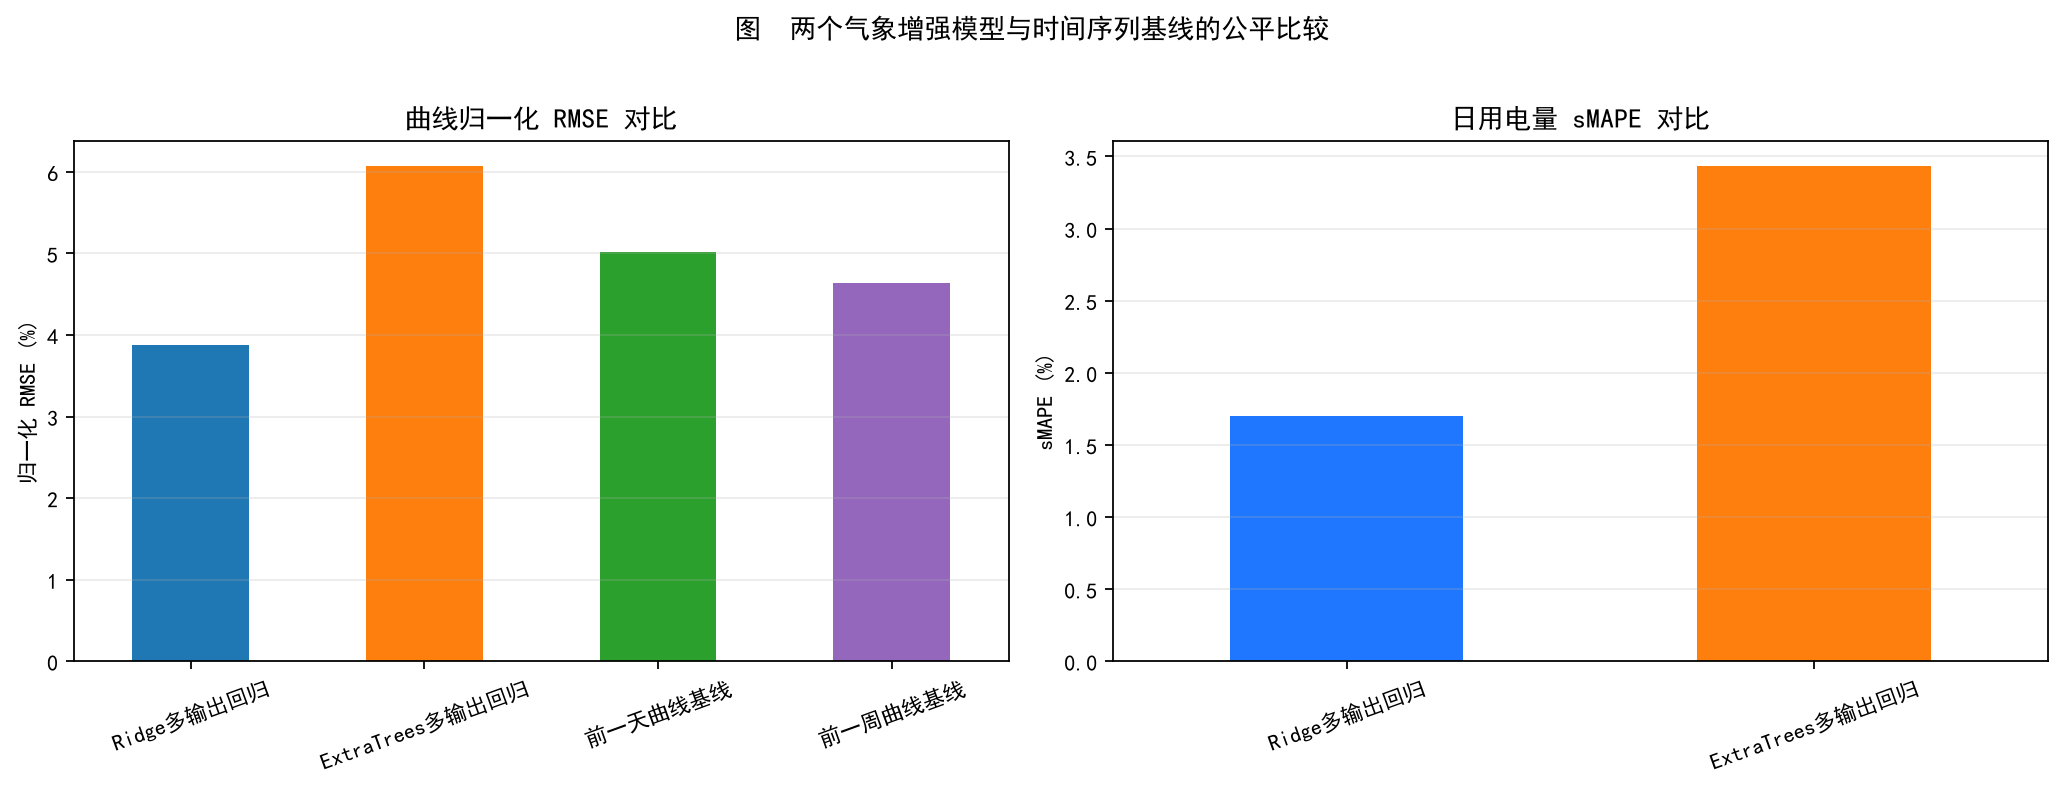

In [9]:
# 图1：测试集某一天的完整预测曲线（0%模拟气象预报）
from IPython.display import Image, display
example_idx = min(10, len(test_dates) - 1)
slot_axis = np.arange(144) / 6
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(slot_axis, Y_test[example_idx], color='black', lw=1.6, label='真实负荷')
for name, color in [('Ridge多输出回归', '#1f77b4'), ('ExtraTrees多输出回归', '#ff7f0e')]:
    ax.plot(slot_axis, predictions[name][example_idx], color=color, lw=1.2, label=f'{name}（0%模拟气象）')
ax.plot(slot_axis, day_profiles[test_dates[example_idx] - pd.Timedelta(days=7)],
        color='#2ca02c', ls='--', lw=1.0, label='前一周基线')
ax.set_title(f'图  {test_dates[example_idx].date()}：144点日内负荷预测')
ax.set_xlabel('时刻'); ax.set_ylabel('负荷 (kW)')
ax.set_xticks(range(0, 25, 2)); ax.grid(alpha=0.3); ax.legend(); fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_B11_curve.png', dpi=160, bbox_inches='tight')
display(Image(filename=f'{FIG_DIR}/fig_B11_curve.png'))
plt.close(fig)

# 图2：测试期日用电量对比
fig, ax = plt.subplots(figsize=(13, 4.8))
actual_energy = Y_test.sum(axis=1) / 6
ax.plot(test_dates, actual_energy, color='black', lw=1.5, label='真实日用电量')
for name, color in [('Ridge多输出回归', '#1f77b4'), ('ExtraTrees多输出回归', '#ff7f0e')]:
    ax.plot(test_dates, predictions[name].sum(axis=1) / 6, color=color, lw=1.1, label=f'{name}（0%模拟气象）')
ax.set_title('图  测试期日用电量预测')
ax.set_xlabel('目标日期'); ax.set_ylabel('日用电量 (kWh)')
ax.grid(alpha=0.3); ax.legend(); fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_B11_energy.png', dpi=160, bbox_inches='tight')
display(Image(filename=f'{FIG_DIR}/fig_B11_energy.png'))
plt.close(fig)

# 图3：公平的百分比指标对比
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
all_curve_metrics.plot(x='模型', y='曲线归一化RMSE%', kind='bar', ax=axes[0],
                       color=['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd'], legend=False)
axes[0].set_title('曲线归一化 RMSE 对比'); axes[0].set_ylabel('归一化 RMSE (%)'); axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=20); axes[0].grid(alpha=0.25, axis='y')
summary_plot = summary_metrics[summary_metrics['目标'] == '日用电量(kWh)']
summary_plot.plot(x='模型', y='sMAPE%', kind='bar', ax=axes[1],
                  color=['#1f77ff', '#ff7f0e'], legend=False)
axes[1].set_title('日用电量 sMAPE 对比'); axes[1].set_ylabel('sMAPE (%)'); axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=20); axes[1].grid(alpha=0.25, axis='y')
fig.suptitle('图  两个气象增强模型与时间序列基线的公平比较', y=1.02); fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_B11_metrics.png', dpi=160, bbox_inches='tight')
display(Image(filename=f'{FIG_DIR}/fig_B11_metrics.png'))
plt.close(fig)

## 9. 总结：双模型真实气象训练与模拟预报测试

本版本把信息边界统一为：Ridge 和 ExtraTrees 都使用训练期目标日真实气象特征进行拟合，测试期都使用模拟气象预报特征。主测试情景为 0% 接近度，即前一日持久性气象；0% 至 100% 的情景曲线用于补充分析气象预报误差的影响。

在主测试情景下，Ridge 的曲线 RMSE 为 2,494.50 kW，ExtraTrees 为 3,910.83 kW；Ridge 的 MAE 和 sMAPE 也更低，分别为 1,767.05 kW、2.72%，而 ExtraTrees 为 3,142.59 kW、4.77%。因此，在当前测试窗、当前气象摘要、当前模拟方式和固定参数下，Ridge 仍然优于 ExtraTrees。

这个结论只描述当前条件下的比较结果，不能推广为 Ridge 在所有时期都优于树模型。100% 气象接近度结果是理想真实气象参考，不属于严格部署评估；要评价真实业务价值，还需要历史天气预报回放、多年份滚动验证和训练期内部调参。

## 附录：两个算法与真实气象训练、模拟气象测试

### A.1 Ridge 多输出回归

Ridge 在多输出线性回归中加入 L2 正则项：

```text
min_B ||Y - XB||_F² + α||B||_F²
```

本版本的输入 `X` 同时包含前一天、前一周历史负荷曲线、日历特征，以及目标日天气摘要。训练阶段天气摘要使用真实观测；测试阶段替换为模拟预报。

### A.2 ExtraTrees 多输出回归

ExtraTrees 由多棵随机化回归树组成，每棵树在随机候选特征和切分阈值上递归分裂，叶节点输出 144 维负荷均值向量，最终对所有树的预测取平均：

```text
ŷ = (1/T) Σ(t=1 到 T) f_t(x)
```

它用于检验气象与历史负荷之间的阈值、非线性和特征交互。与 Ridge 一样，训练阶段使用真实天气，测试阶段使用模拟气象预报。

### A.3 气象模拟情景

```text
模拟气象 = 前一日气象 + 接近度 ×（目标日真实气象 − 前一日气象）
```

0% 是前一日持久性天气，100% 是目标日真实天气的理想参考。两种模型在相同情景下预测，保证比较公平。